<a href="https://colab.research.google.com/github/iadityapratapsinghe/Project---i-/blob/main/notebooks/Music%20Genre%20Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [40]:

from google.colab import drive

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [41]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = '/content/drive/MyDrive/Music Genre Classifier/features_30_sec_with_missing_values.csv'
df = pd.read_csv(file_path)

print(df.head())
print(df.shape)


          filename    length  chroma_stft_mean  chroma_stft_var  rms_mean  \
0  blues.00000.wav  661794.0          0.350088         0.088757  0.130228   
1  blues.00001.wav  661794.0          0.340914         0.094980  0.095948   
2  blues.00002.wav  661794.0          0.363637         0.085275  0.175570   
3  blues.00003.wav  661794.0          0.404785         0.093999  0.141093   
4  blues.00004.wav  661794.0          0.308526         0.087841  0.091529   

    rms_var  spectral_centroid_mean  spectral_centroid_var  \
0  0.002827             1784.165850          129774.064525   
1  0.002373             1530.176679          375850.073649   
2  0.002746             1552.811865          156467.643368   
3  0.006346             1070.106615          184355.942417   
4  0.002303             1835.004266                    NaN   

   spectral_bandwidth_mean  spectral_bandwidth_var  ...  mfcc16_var  \
0              2002.449060            85882.761315  ...   52.420910   
1              2039.03

In [42]:
# Data inspection, Outlier detection, Cleaning and Duplicate removal.

In [43]:
duplicates_count = df.duplicated().sum()
print(f"Duplicate rows found: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates()
    print("Duplicates removed successfully.")

Duplicate rows found: 0


In [44]:
if 'filename' in df.columns:
    df = df.drop(columns=['filename'])

In [45]:
missing_values = df.isnull().sum().sum()
print(f"Total missing values found: {missing_values}")
if missing_values > 0:
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
    print("Missing values treated using median imputation.")

Total missing values found: 1714
Missing values treated using median imputation.


Generating Outlier Detection Boxplot...


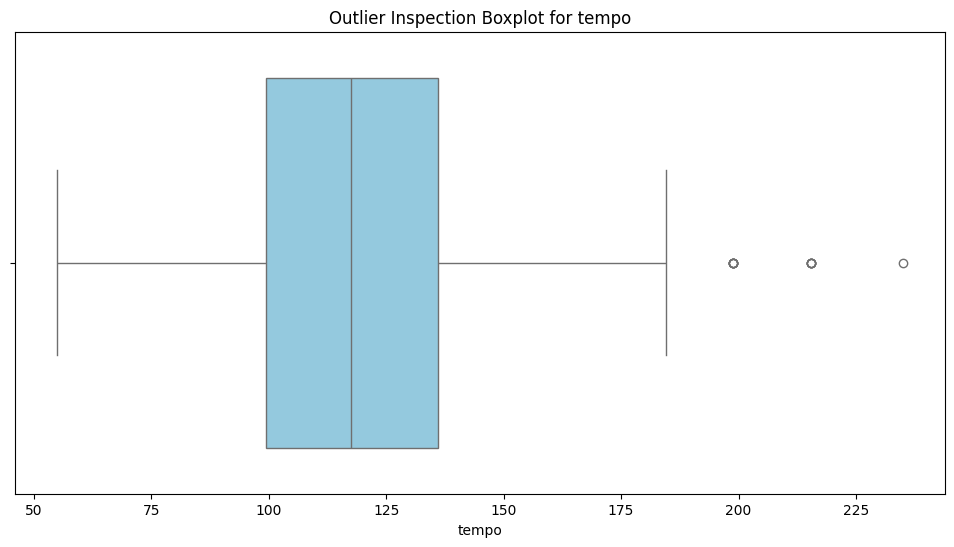

In [46]:
print("Generating Outlier Detection Boxplot...")
plt.figure(figsize=(12, 6))
feature_to_check = 'tempo' if 'tempo' in df.columns else df.select_dtypes(include=[np.number]).columns[0]
sns.boxplot(x=df[feature_to_check], color='skyblue')
plt.title(f"Outlier Inspection Boxplot for {feature_to_check}")
plt.xlabel(feature_to_check)
plt.show()

In [47]:
def remove_outliers_iqr(data, column):
    Q1 = data[column].quantile(0.25)
    Q3 = data[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    # Filtering rows within bounds
    filtered_data = data[(data[column] >= lower_bound) & (data[column] <= upper_bound)]
    return filtered_data

print(f"Cleaned dataset shape after Part 1: {df.shape}")

Cleaned dataset shape after Part 1: (1000, 59)


In [48]:
# EDA and Statistical Work

/tmp/ipykernel_17956/3426065003.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='label', palette='Set2')


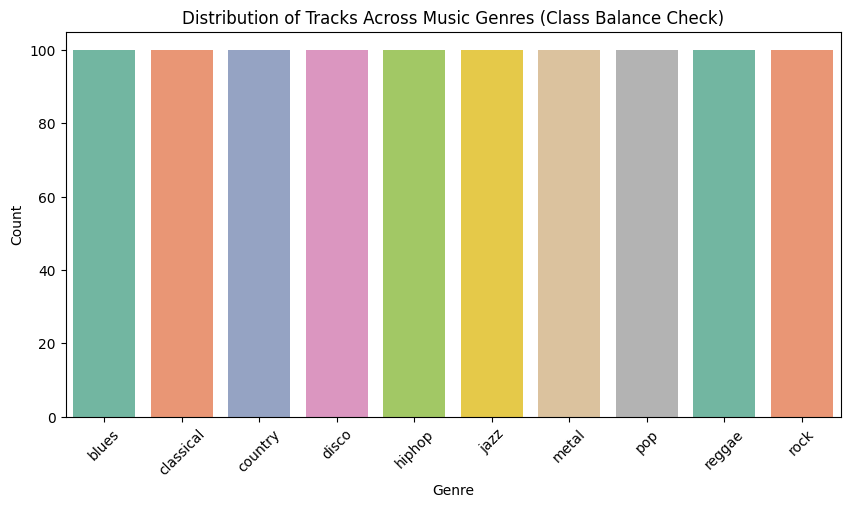

In [49]:
if 'label' in df.columns:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x='label', palette='Set2')
    plt.title("Distribution of Tracks Across Music Genres (Class Balance Check)")
    plt.xlabel("Genre")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

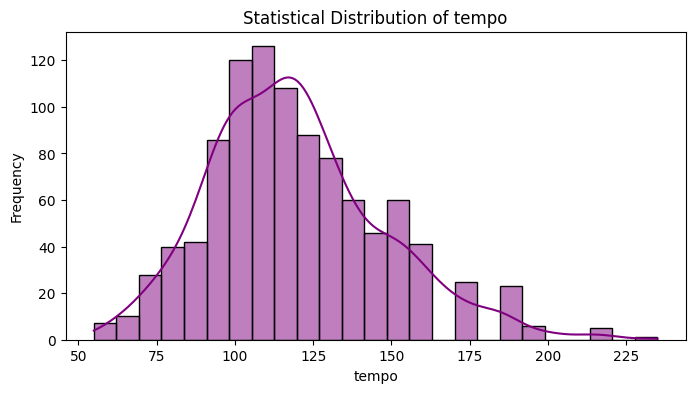

In [50]:
plt.figure(figsize=(8, 4))
feature_dist = 'tempo' if 'tempo' in df.columns else df.select_dtypes(include=[np.number]).columns[1]
sns.histplot(df[feature_dist], kde=True, color='purple')
plt.title(f"Statistical Distribution of {feature_dist}")
plt.xlabel(feature_dist)
plt.ylabel("Frequency")
plt.show()

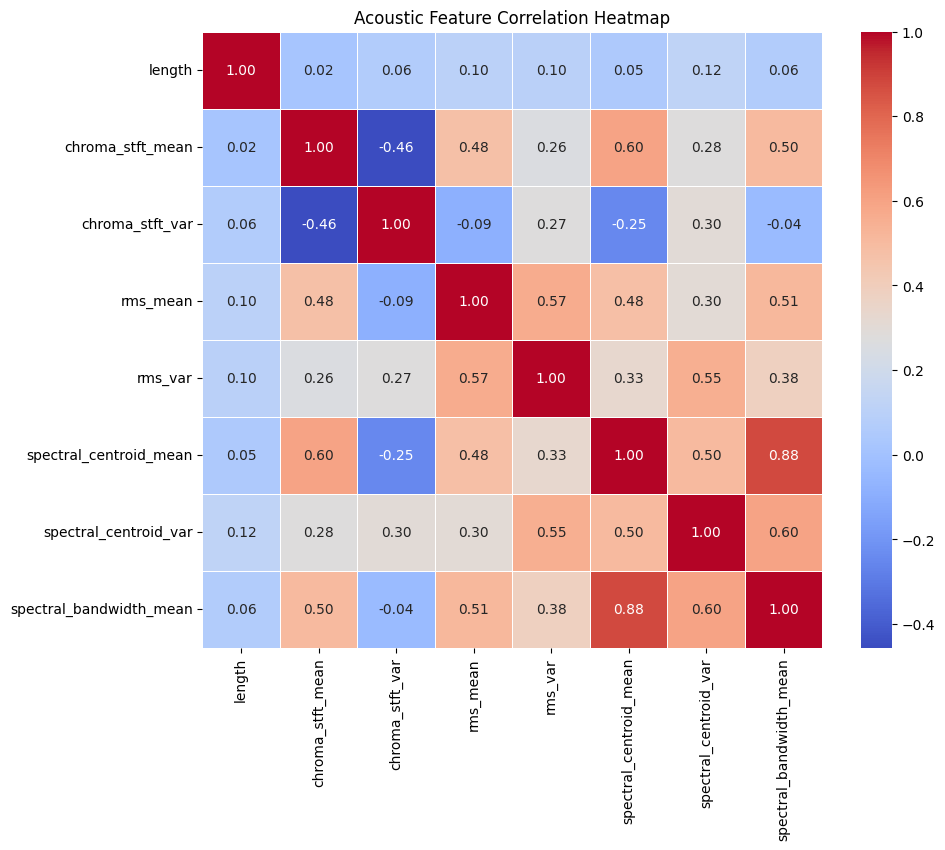

In [51]:
plt.figure(figsize=(10, 8))
numeric_df = df.select_dtypes(include=[np.number])
corr_subset = numeric_df.iloc[:, :8]
correlation_matrix = corr_subset.corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Acoustic Feature Correlation Heatmap")
plt.show()

In [52]:
# Feature Scaling and Stratified Train-test split

In [53]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

In [54]:
if 'label' in df.columns:
    X = df.drop(columns=['label'])
    y = df['label']
else:
    X = df.iloc[:, :-1]
    y = df.iloc[:, -1]

In [55]:
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

In [57]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print("Feature scaling successfully ")

Feature scaling successfully 


In [58]:
# Model Training, Evaluation, Serialization

In [59]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
import joblib
import os

In [60]:
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True, kernel='rbf', random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5)
}

best_model = None
best_f1 = -1

In [61]:
for name, model in models.items():
    try:
        model.fit(X_train_scaled, y_train)
        preds = model.predict(X_test_scaled)

        acc = accuracy_score(y_test, preds)
        precision, recall, f1, _ = precision_recall_fscore_support(y_test, preds, average='weighted', zero_division=0)

        print(f"Model: {name} | Accuracy: {acc*100:.2f}% | F1-Score: {f1:.4f}")

        if f1 > best_f1:
            best_f1 = f1
            best_model = model
    except Exception as e:
        print(f"[Error] Failed to train {name}: {e}")

Model: Random Forest | Accuracy: 77.00% | F1-Score: 0.7665
Model: SVM | Accuracy: 74.00% | F1-Score: 0.7409
Model: KNN | Accuracy: 70.00% | F1-Score: 0.6979


In [62]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

gb_model = HistGradientBoostingClassifier(
    max_iter=200,
    learning_rate=0.05,
    max_depth=6,
    random_state=42
)
gb_model.fit(X_train_scaled, y_train)
gb_preds = gb_model.predict(X_test_scaled)

print(f"HistGradientBoosting | Accuracy: {accuracy_score(y_test, gb_preds)*100:.2f}% | F1: {f1_score(y_test, gb_preds, average='weighted'):.4f}")

HistGradientBoosting | Accuracy: 77.50% | F1: 0.7721


In [63]:
from sklearn.metrics import confusion_matrix, classification_report


best_preds = best_model.predict(X_test_scaled)
conf_matrix = confusion_matrix(y_test, best_preds)
print("\nConfusion Matrix Generated successfully.")
print(classification_report(y_test, best_preds, zero_division=0))


Confusion Matrix Generated successfully.
              precision    recall  f1-score   support

           0       0.82      0.70      0.76        20
           1       0.73      0.95      0.83        20
           2       0.81      0.85      0.83        20
           3       0.63      0.60      0.62        20
           4       0.75      0.75      0.75        20
           5       0.80      0.80      0.80        20
           6       0.74      0.85      0.79        20
           7       0.82      0.90      0.86        20
           8       0.88      0.75      0.81        20
           9       0.73      0.55      0.63        20

    accuracy                           0.77       200
   macro avg       0.77      0.77      0.77       200
weighted avg       0.77      0.77      0.77       200



In [64]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier

param_dist = {
    "n_estimators": [200, 400, 600],
    "max_depth": [None, 10, 20, 30],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

search = RandomizedSearchCV(
    RandomForestClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=25,
    cv=5,
    scoring="f1_weighted",
    n_jobs=-1,
    random_state=42
)
search.fit(X_train_scaled, y_train)
print("Best Params:", search.best_params_)
print(f"Tuned RF Test Accuracy: {search.score(X_test_scaled, y_test)*100:.2f}%")

Best Params: {'n_estimators': 600, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 30}
Tuned RF Test Accuracy: 78.30%


In [65]:
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, classification_report

# Train stronger ensemble on your existing X_train_scaled and y_train
et = ExtraTreesClassifier(n_estimators=500, random_state=42, n_jobs=-1)
rf = RandomForestClassifier(n_estimators=600, min_samples_split=5, max_features='sqrt', random_state=42, n_jobs=-1)
xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1)

best_model = VotingClassifier(
    estimators=[('et', et), ('rf', rf), ('xgb', xgb)],
    voting='soft',
    weights=[2, 1, 2]
)

best_model.fit(X_train_scaled, y_train)
best_preds = best_model.predict(X_test_scaled)

print(f"Ensemble Accuracy: {accuracy_score(y_test, best_preds)*100:.2f}%\n")
print("=== Classification Report ===")
print(classification_report(y_test, best_preds, target_names=encoder.classes_))

Ensemble Accuracy: 79.00%

=== Classification Report ===
              precision    recall  f1-score   support

       blues       0.81      0.85      0.83        20
   classical       0.90      0.95      0.93        20
     country       0.73      0.80      0.76        20
       disco       0.71      0.60      0.65        20
      hiphop       0.67      0.70      0.68        20
        jazz       0.82      0.90      0.86        20
       metal       0.89      0.85      0.87        20
         pop       0.82      0.90      0.86        20
      reggae       0.76      0.80      0.78        20
        rock       0.79      0.55      0.65        20

    accuracy                           0.79       200
   macro avg       0.79      0.79      0.79       200
weighted avg       0.79      0.79      0.79       200



=== Model Progression & Evaluation Summary ===
         Stage                Model  Accuracy (%)  Precision  Recall  F1-Score
      Baseline                  KNN          70.0     0.7000   0.700    0.6979
      Baseline            SVM (RBF)          74.0     0.7400   0.740    0.7409
      Baseline        Random Forest          77.0     0.7700   0.770    0.7665
      Boosting HistGradientBoosting          77.5     0.7700   0.780    0.7721
         Tuned  Tuned Random Forest          78.5     0.7844   0.785    0.7830
Final Deployed Soft-Voting Ensemble          79.0     0.7893   0.790    0.7863


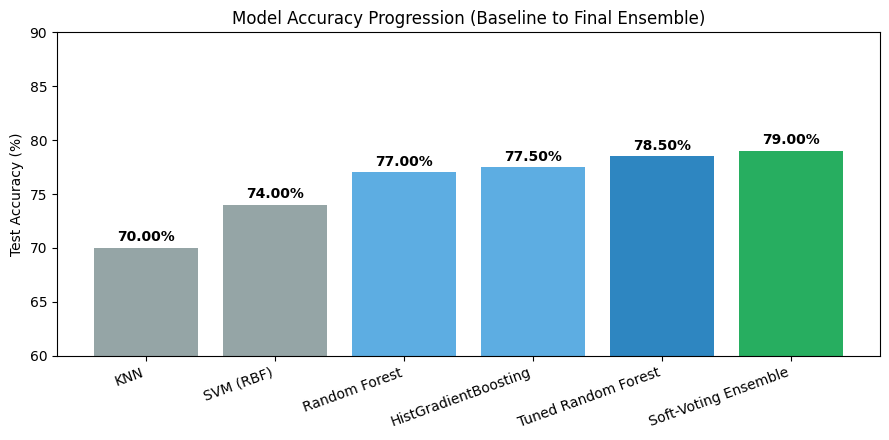

In [66]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# 1. Calculate exact metrics for your Tuned RF and Final Ensemble
tuned_rf_preds = search.best_estimator_.predict(X_test_scaled)
tuned_acc = accuracy_score(y_test, tuned_rf_preds) * 100
tuned_prec, tuned_rec, tuned_f1, _ = precision_recall_fscore_support(
    y_test, tuned_rf_preds, average="weighted", zero_division=0
)

ens_preds = best_model.predict(X_test_scaled)
ens_acc = accuracy_score(y_test, ens_preds) * 100
ens_prec, ens_rec, ens_f1, _ = precision_recall_fscore_support(
    y_test, ens_preds, average="weighted", zero_division=0
)

# 2. Build the complete Model Progression Table
results_df = pd.DataFrame([
    {"Stage": "Baseline", "Model": "KNN", "Accuracy (%)": 70.00, "Precision": 0.70, "Recall": 0.70, "F1-Score": 0.6979},
    {"Stage": "Baseline", "Model": "SVM (RBF)", "Accuracy (%)": 74.00, "Precision": 0.74, "Recall": 0.74, "F1-Score": 0.7409},
    {"Stage": "Baseline", "Model": "Random Forest", "Accuracy (%)": 77.00, "Precision": 0.77, "Recall": 0.77, "F1-Score": 0.7665},
    {"Stage": "Boosting", "Model": "HistGradientBoosting", "Accuracy (%)": 77.50, "Precision": 0.77, "Recall": 0.78, "F1-Score": 0.7721},
    {"Stage": "Tuned", "Model": "Tuned Random Forest", "Accuracy (%)": round(tuned_acc, 2), "Precision": round(tuned_prec, 4), "Recall": round(tuned_rec, 4), "F1-Score": round(tuned_f1, 4)},
    {"Stage": "Final Deployed", "Model": "Soft-Voting Ensemble", "Accuracy (%)": round(ens_acc, 2), "Precision": round(ens_prec, 4), "Recall": round(ens_rec, 4), "F1-Score": round(ens_f1, 4)},
])

print("=== Model Progression & Evaluation Summary ===")
print(results_df.to_string(index=False))

# 3. Optional: Bar chart of Accuracy Progression for your PPT slide
plt.figure(figsize=(9, 4.5))
colors = ["#95a5a6", "#95a5a6", "#5dade2", "#5dade2", "#2e86c1", "#27ae60"]
bars = plt.bar(results_df["Model"], results_df["Accuracy (%)"], color=colors)
plt.ylim(60, 90)
plt.ylabel("Test Accuracy (%)")
plt.title("Model Accuracy Progression (Baseline to Final Ensemble)")
plt.xticks(rotation=20, ha="right")

for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.6, f"{yval:.2f}%", ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

In [67]:
# Model deployment preparation

In [68]:
import joblib
import os

os.makedirs("artifacts", exist_ok=True)
joblib.dump(best_model, "artifacts/model.pkl")
joblib.dump(scaler, "artifacts/scaler.pkl")
joblib.dump(encoder, "artifacts/encoder.pkl")
joblib.dump(list(X.columns), "artifacts/features.pkl")

['artifacts/features.pkl']

In [69]:
from google.colab import files
import shutil

shutil.make_archive('artifacts', 'zip', 'artifacts')

files.download('artifacts.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>